# CIFAR-100 DKD Training, Ablation, and Logging

Training and experiment logging notebook for **Decoupled Knowledge Distillation (DKD, Zhao et al., CVPR 2022)** on CIFAR-100 with the **ResNet32×4 (teacher) $\rightarrow$ ResNet8×4 (student)** pair.

This notebook connects the local codebase modules:
- `src/data/cifar100.py`: official CIFAR-100 Python batch loader, train/eval transforms, and `build_dataloaders()`
- `src/models/resnet.py`: `resnet32x4` teacher and `resnet8x4` student architectures + pretrained teacher loader
- `src/losses/dkd.py`: from-scratch `DistillationLoss` supporting all five experiment modes:
  - `ce`: hard-label cross-entropy baseline
  - `kd`: classical Hinton KD ($\text{TCKD} + (1 - p_t^T)\cdot\text{NCKD}$)
  - `dkd`: full Decoupled KD ($\alpha=1.0, \beta=8.0, T=4.0$, 20-epoch linear warmup)
  - `tckd_only`: Category-A ablation with target-class KD only ($\alpha=1.0, \beta=0.0$)
  - `nckd_only`: Category-A ablation with non-target-class KD only ($\alpha=0.0, \beta=8.0$)
- `src/engine/trainer.py`: training loop, evaluation, `metrics.jsonl` logger, checkpointing (`ckpt_best.pth`, `ckpt_last.pth`), and `benchmark_batch_latency()`.


In [1]:
from pathlib import Path
import json
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import torch

REPO_ROOT = Path.cwd().resolve()
if not (REPO_ROOT / "src").exists():
    REPO_ROOT = REPO_ROOT.parent
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from src.data.cifar100 import build_dataloaders
from src.engine.trainer import (
    EpochMetrics,
    adjust_learning_rate,
    append_metrics_jsonl,
    benchmark_batch_latency,
    build_optimizer,
    evaluate,
    load_config,
    save_checkpoint,
    select_device,
    set_seed,
    train_one_epoch,
)
from src.losses.dkd import (
    DistillationLoss,
    kd_loss,
    kd_loss_from_decoupled_terms,
    nckd_per_sample,
    tckd_per_sample,
)
from src.models.resnet import build_model, load_pretrained_teacher

CONFIG_PATH = REPO_ROOT / "configs" / "cifar100_resnet32x4_resnet8x4.yaml"
cfg = load_config(CONFIG_PATH)
device = select_device("auto")

print("Repository root:", REPO_ROOT)
print("PyTorch version:", torch.__version__)
print("Selected device:", device)
print("Loaded config:  ", cfg)

Matplotlib is building the font cache; this may take a moment.


Repository root: /Users/sufyan.siddiqui/ML-Project
PyTorch version: 2.15.0
Selected device: mps
Loaded config:   {'dataset': 'cifar100', 'teacher': 'resnet32x4', 'student': 'resnet8x4', 'solver': {'optimizer': 'SGD', 'epochs': 240, 'batch_size': 64, 'lr': 0.05, 'momentum': 0.9, 'weight_decay': 0.0005, 'lr_decay_stages': [150, 180, 210], 'lr_decay_rate': 0.1}, 'dkd': {'ce_weight': 1.0, 'alpha': 1.0, 'beta': 8.0, 'temperature': 4.0, 'warmup_epochs': 20}, 'preprocess': {'train': ['random_crop_32_pad_4', 'random_horizontal_flip', 'to_tensor', 'normalize'], 'test': ['to_tensor', 'normalize'], 'mean': [0.5071, 0.4867, 0.4408], 'std': [0.2675, 0.2565, 0.2761]}}


In [ ]:
# Download CIFAR-100 (about 161 MB) into data/ the first time this runs.
# Skipped when data/cifar-100-python already has train, test, and meta.
from scripts.setup_project import ensure_cifar100

ensure_cifar100()

## 1. Load CIFAR-100 DataLoaders and Verify Pretrained Teacher

We build the training and evaluation `DataLoader` objects using `src/data/cifar100.py` and load the frozen plain-CE `ResNet32x4` teacher checkpoint (`checkpoints/cifar_teachers/resnet32x4_vanilla/ckpt_epoch_240.pth`). In Table 6 of the DKD paper, the teacher's CIFAR-100 test top-1 accuracy is **79.42%**.

In [2]:
set_seed(42)

train_loader, test_loader, raw_data = build_dataloaders(
    data_dir=REPO_ROOT / "data" / "cifar-100-python",
    batch_size=cfg["solver"]["batch_size"],
    eval_batch_size=128,
    num_workers=0,
    pin_memory=(device.type == "cuda"),
    seed=42,
)

teacher = load_pretrained_teacher(
    num_classes=100,
    device=device,
    download_if_missing=True,
)

teacher_stats = evaluate(teacher, test_loader, device=device)
print(f"Train batches: {len(train_loader)} (batch_size={cfg['solver']['batch_size']})")
print(f"Test samples:  {int(teacher_stats['samples'])}")
print(
    f"Teacher ({cfg['teacher']}) Test Accuracy -> "
    f"Top-1: {teacher_stats['top1']:.2f}% (Paper: 79.42%) | "
    f"Top-5: {teacher_stats['top5']:.2f}% | CE Loss: {teacher_stats['loss']:.4f}"
)

Train batches: 782 (batch_size=64)
Test samples:  10000
Teacher (resnet32x4) Test Accuracy -> Top-1: 79.42% (Paper: 79.42%) | Top-5: 94.58% | CE Loss: 0.8833


## 2. Real-Batch DKD Reformulation Check & Batch-Timing Benchmark

Before training, we verify two core properties on a real CIFAR-100 training batch:
1. **Exact algebraic identity (Equation 1)**: $\mathcal{L}_{\text{KD}} = \text{TCKD} + (1 - p_t^T)\,\text{NCKD}$, and how confident teacher predictions $(p_t^T \to 1)$ suppress the non-target dark knowledge weight $(1 - p_t^T)$.
2. **Batch step latency (`ms/batch`)**: comparing `ce`, `kd`, `dkd`, `tckd_only`, and `nckd_only` on the active device to confirm DKD adds no extra forward pass over vanilla KD.

In [3]:
sample_images, sample_targets = next(iter(train_loader))
sample_images = sample_images.to(device)
sample_targets = sample_targets.to(device)

student_probe = build_model(cfg["student"], num_classes=100).to(device)
student_probe.eval()

with torch.no_grad():
    logits_t = teacher(sample_images)
    logits_s = student_probe(sample_images)

    T = float(cfg["dkd"]["temperature"])
    kd_direct = kd_loss(logits_s, logits_t, temperature=T).item()
    kd_decoupled = kd_loss_from_decoupled_terms(logits_s, logits_t, sample_targets, temperature=T).item()

    probs_t_T1 = torch.softmax(logits_t, dim=1)
    probs_t_T4 = torch.softmax(logits_t / T, dim=1)
    pt_T1 = probs_t_T1.gather(1, sample_targets.view(-1, 1)).squeeze(1)
    pt_T4 = probs_t_T4.gather(1, sample_targets.view(-1, 1)).squeeze(1)

    tckd_vec = tckd_per_sample(logits_s, logits_t, sample_targets, temperature=T)
    nckd_vec = nckd_per_sample(logits_s, logits_t, sample_targets, temperature=T)

print(f"Classical KD (direct KL * T^2):      {kd_direct:.8f}")
print(f"Decoupled identity Eq. (1) * T^2:    {kd_decoupled:.8f}")
print(f"Absolute difference:                 {abs(kd_direct - kd_decoupled):.2e}")
print(f"Mean teacher target prob p_t^T (T=1): {pt_T1.mean().item():.4f} (coupling 1 - p_t^T = {(1 - pt_T1).mean().item():.4f})")
print(f"Mean teacher target prob p_t^T (T=4): {pt_T4.mean().item():.4f} (coupling 1 - p_t^T = {(1 - pt_T4).mean().item():.4f})")

timings_ms = benchmark_batch_latency(
    student=student_probe,
    teacher=teacher,
    batch_size=cfg["solver"]["batch_size"],
    warmup_steps=3,
    timed_steps=10,
    device=device,
)
print("\nBatch step latency benchmark (ms/batch):")
for mode_name, ms in timings_ms.items():
    print(f"  {mode_name:10s}: {ms:.2f} ms/batch")

Classical KD (direct KL * T^2):      10.27972794
Decoupled identity Eq. (1) * T^2:    10.27972698
Absolute difference:                 9.54e-07
Mean teacher target prob p_t^T (T=1): 0.9963 (coupling 1 - p_t^T = 0.0037)
Mean teacher target prob p_t^T (T=4): 0.2310 (coupling 1 - p_t^T = 0.7690)



Batch step latency benchmark (ms/batch):
  ce        : 57.25 ms/batch
  kd        : 123.30 ms/batch
  dkd       : 127.06 ms/batch
  tckd_only : 125.80 ms/batch
  nckd_only : 128.77 ms/batch


## 3. Training & Logging Runner

`run_training_session()` runs any of the 5 experiment modes (`dkd`, `kd`, `ce`, `tckd_only`, `nckd_only`) and logs every epoch to `outputs/<run_name>/metrics.jsonl` while saving `ckpt_last.pth` and `ckpt_best.pth`.

- For the **full reproduction or ablation run**, set `EPOCHS = 240` and `MAX_BATCHES = None` (matches `configs/cifar100_resnet32x4_resnet8x4.yaml`).
- Below, we execute a short **3-epoch logged verification run** (`MAX_BATCHES = 25`) so the logging pipeline, checkpointing, and diagnostic plots are populated and verified end-to-end.

In [4]:
def run_training_session(
    mode: str = "dkd",
    epochs: int | None = None,
    max_batches: int | None = None,
    run_name: str | None = None,
    seed: int = 42,
    log_interval: int = 0,
    reset_log: bool = True,
) -> tuple[Path, list[dict]]:
    """Train ResNet8x4 student under the specified mode and record epoch metrics to JSONL."""
    set_seed(seed)
    solver_cfg = cfg["solver"]
    dkd_cfg = cfg["dkd"]

    total_epochs = int(epochs if epochs is not None else solver_cfg["epochs"])
    base_lr = float(solver_cfg["lr"])
    decay_stages = [int(s) for s in solver_cfg["lr_decay_stages"]]
    decay_rate = float(solver_cfg["lr_decay_rate"])

    out_dir = REPO_ROOT / "outputs" / (run_name or mode)
    out_dir.mkdir(parents=True, exist_ok=True)
    metrics_path = out_dir / "metrics.jsonl"
    if reset_log and metrics_path.exists():
        metrics_path.unlink()

    student = build_model(cfg["student"], num_classes=100).to(device)
    active_teacher = None if mode == "ce" else teacher

    criterion = DistillationLoss(
        mode=mode,
        ce_weight=float(dkd_cfg["ce_weight"]),
        alpha=float(dkd_cfg["alpha"]),
        beta=float(dkd_cfg["beta"]),
        temperature=float(dkd_cfg["temperature"]),
        warmup_epochs=int(dkd_cfg["warmup_epochs"]),
    )
    optimizer = build_optimizer(
        student,
        lr=base_lr,
        momentum=float(solver_cfg["momentum"]),
        weight_decay=float(solver_cfg["weight_decay"]),
    )

    history: list[dict] = []
    best_top1 = 0.0

    print(f"--- Starting run: mode={mode} | epochs={total_epochs} | out_dir={out_dir.relative_to(REPO_ROOT)} ---")
    for epoch in range(1, total_epochs + 1):
        t0 = time.perf_counter()
        lr = adjust_learning_rate(
            optimizer,
            epoch=epoch,
            base_lr=base_lr,
            decay_stages=decay_stages,
            decay_rate=decay_rate,
        )
        train_stats = train_one_epoch(
            student=student,
            teacher=active_teacher,
            criterion=criterion,
            optimizer=optimizer,
            train_loader=train_loader,
            device=device,
            epoch=epoch,
            max_batches=max_batches,
            log_interval=log_interval,
        )
        test_stats = evaluate(
            model=student,
            data_loader=test_loader,
            device=device,
            max_batches=max_batches,
        )
        epoch_sec = time.perf_counter() - t0

        is_best = test_stats["top1"] >= best_top1
        if is_best:
            best_top1 = test_stats["top1"]

        record = EpochMetrics(
            epoch=epoch,
            lr=lr,
            train_loss=train_stats["loss"],
            train_loss_ce=train_stats["loss_ce"],
            train_loss_distill=train_stats["loss_distill"],
            train_top1=train_stats["top1"],
            test_loss=test_stats["loss"],
            test_top1=test_stats["top1"],
            test_top5=test_stats["top5"],
            avg_batch_ms=train_stats["avg_batch_ms"],
            epoch_sec=epoch_sec,
        )
        append_metrics_jsonl(out_dir, record)
        history.append(record.__dict__)

        save_checkpoint(out_dir, "ckpt_last.pth", student, optimizer, epoch, best_top1, mode, cfg)
        if is_best:
            save_checkpoint(out_dir, "ckpt_best.pth", student, optimizer, epoch, best_top1, mode, cfg)

        print(
            f"Epoch {epoch:03d}/{total_epochs:03d} | lr={lr:.4f} | "
            f"train_loss={record.train_loss:.4f} (ce={record.train_loss_ce:.4f}, distill={record.train_loss_distill:.4f}) | "
            f"train_top1={record.train_top1:.2f}% | test_top1={record.test_top1:.2f}% (best={best_top1:.2f}%) | "
            f"batch={record.avg_batch_ms:.1f}ms | {epoch_sec:.1f}s"
        )

    return out_dir, history

In [5]:
# Set EPOCHS = 240 and MAX_BATCHES = None for full reproduction / ablation runs.
EPOCHS = 3
MAX_BATCHES = 25

dkd_dir, dkd_history = run_training_session(
    mode="dkd",
    epochs=EPOCHS,
    max_batches=MAX_BATCHES,
    run_name="smoke_dkd",
)
kd_dir, kd_history = run_training_session(
    mode="kd",
    epochs=EPOCHS,
    max_batches=MAX_BATCHES,
    run_name="smoke_kd",
)

--- Starting run: mode=dkd | epochs=3 | out_dir=outputs/smoke_dkd ---


Epoch 001/003 | lr=0.0500 | train_loss=5.7390 (ce=4.5374, distill=1.2016) | train_top1=2.50% | test_top1=4.81% (best=4.81%) | batch=126.2ms | 4.5s


Epoch 002/003 | lr=0.0500 | train_loss=6.6149 (ce=4.2714, distill=2.3436) | train_top1=5.44% | test_top1=6.41% (best=6.41%) | batch=127.2ms | 4.6s


Epoch 003/003 | lr=0.0500 | train_loss=7.6578 (ce=4.2132, distill=3.4446) | train_top1=6.00% | test_top1=5.44% (best=6.41%) | batch=133.1ms | 4.8s
--- Starting run: mode=kd | epochs=3 | out_dir=outputs/smoke_kd ---


Epoch 001/003 | lr=0.0500 | train_loss=15.5910 (ce=4.6683, distill=10.9228) | train_top1=3.06% | test_top1=3.00% (best=3.00%) | batch=125.8ms | 4.5s


Epoch 002/003 | lr=0.0500 | train_loss=14.4771 (ce=4.4246, distill=10.0525) | train_top1=4.19% | test_top1=4.03% (best=4.03%) | batch=124.8ms | 4.6s


Epoch 003/003 | lr=0.0500 | train_loss=14.1090 (ce=4.2260, distill=9.8830) | train_top1=5.25% | test_top1=6.28% (best=6.28%) | batch=130.9ms | 4.8s


## 4. Inspecting `metrics.jsonl` Logs and Plotting Training Curves

The helper functions below read `metrics.jsonl` from any run directory under `outputs/` (whether produced inside this notebook or from CLI runs via `scripts/train.py --mode ...`) and plot:
1. Total training loss & distillation warmup progression
2. Test Top-1 accuracy across epochs
3. Average batch step latency (`ms/batch`) across runs

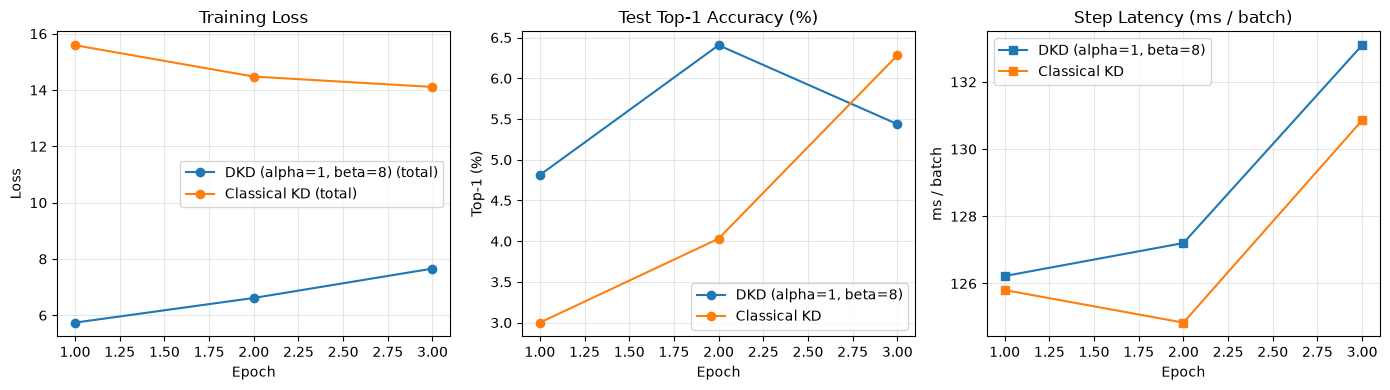

Saved files in outputs/smoke_dkd -> ['ckpt_best.pth', 'ckpt_last.pth', 'metrics.jsonl']


In [6]:
def load_metrics_log(run_dir: Path) -> list[dict]:
    log_file = Path(run_dir) / "metrics.jsonl"
    if not log_file.exists():
        raise FileNotFoundError(f"No metrics.jsonl found in {run_dir}")
    with log_file.open("r", encoding="utf-8") as handle:
        return [json.loads(line) for line in handle if line.strip()]


def plot_experiment_logs(run_dirs: dict[str, Path]) -> None:
    fig, axes = plt.subplots(1, 3, figsize=(14, 4))

    for label, rdir in run_dirs.items():
        rows = load_metrics_log(rdir)
        epochs_x = [r["epoch"] for r in rows]
        train_loss = [r["train_loss"] for r in rows]
        test_top1 = [r["test_top1"] for r in rows]
        batch_ms = [r["avg_batch_ms"] for r in rows]

        axes[0].plot(epochs_x, train_loss, marker="o", label=f"{label} (total)")
        axes[1].plot(epochs_x, test_top1, marker="o", label=label)
        axes[2].plot(epochs_x, batch_ms, marker="s", label=label)

    axes[0].set_title("Training Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].grid(True, alpha=0.3)
    axes[0].legend()

    axes[1].set_title("Test Top-1 Accuracy (%)")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Top-1 (%)")
    axes[1].grid(True, alpha=0.3)
    axes[1].legend()

    axes[2].set_title("Step Latency (ms / batch)")
    axes[2].set_xlabel("Epoch")
    axes[2].set_ylabel("ms / batch")
    axes[2].grid(True, alpha=0.3)
    axes[2].legend()

    plt.tight_layout()
    plt.show()


plot_experiment_logs({"DKD (alpha=1, beta=8)": dkd_dir, "Classical KD": kd_dir})
print("Saved files in", dkd_dir.relative_to(REPO_ROOT), "->", sorted(p.name for p in dkd_dir.iterdir()))